In [1]:
import datetime as dt
import sys
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from utilities.preprocessor import *
from utilities.values import *

data_dir = '../data/'

### Monthly trip patterns by hour (raw timestamps, no conversion)

Weekday trips peak at the morning and evening commute (about 8am and 5-6pm New York time).
If a file's timestamps are in New York time, its peaks line up with those hours.
If they are in UTC, the same peaks show up 4-5 hours later (about 1pm and 10pm).

In [2]:
# read every raw file (2020 and 2021) in calendar order, keeping track of which file each trip came from
raw_files = sorted(
    [f for year in ['2020', '2021'] for f in Path(data_dir + 'raw/' + year).iterdir() if f.suffix == '.csv'],
    key = lambda f: pd.to_datetime(f.stem, format = '%B%Y'),
)
file_order = [f.stem for f in raw_files]

monthly_frames = []
for f in raw_files:
    df = pd.read_csv(f, usecols = ['starttime'])
    df['file'] = f.stem
    monthly_frames.append(df)
trips_df = pd.concat(monthly_frames, ignore_index = True)

# timestamps exactly as written in the files (no timezone conversion)
trips_df['starttime'] = pd.to_datetime(trips_df['starttime'])
trips_df['hour'] = trips_df['starttime'].dt.hour

# weekdays only, so the commute peaks are clear
weekday_trips_df = trips_df[trips_df['starttime'].dt.dayofweek < 5]

In [3]:
# % of each file's weekday trips that start in each hour (each row adds up to 100)
hourly_share_df = (
    pd.crosstab(weekday_trips_df['file'], weekday_trips_df['hour'], normalize = 'index')
    .reindex(file_order) * 100
)

# summary per file: local-time files peak at 8am or 5-6pm and are quietest around 3am
summary_df = pd.DataFrame({
    'busiest hour': hourly_share_df.idxmax(axis = 1),
    'quietest hour': hourly_share_df.idxmin(axis = 1),
    '% of trips 0-4am': hourly_share_df.loc[:, 0:4].sum(axis = 1).round(1),
})

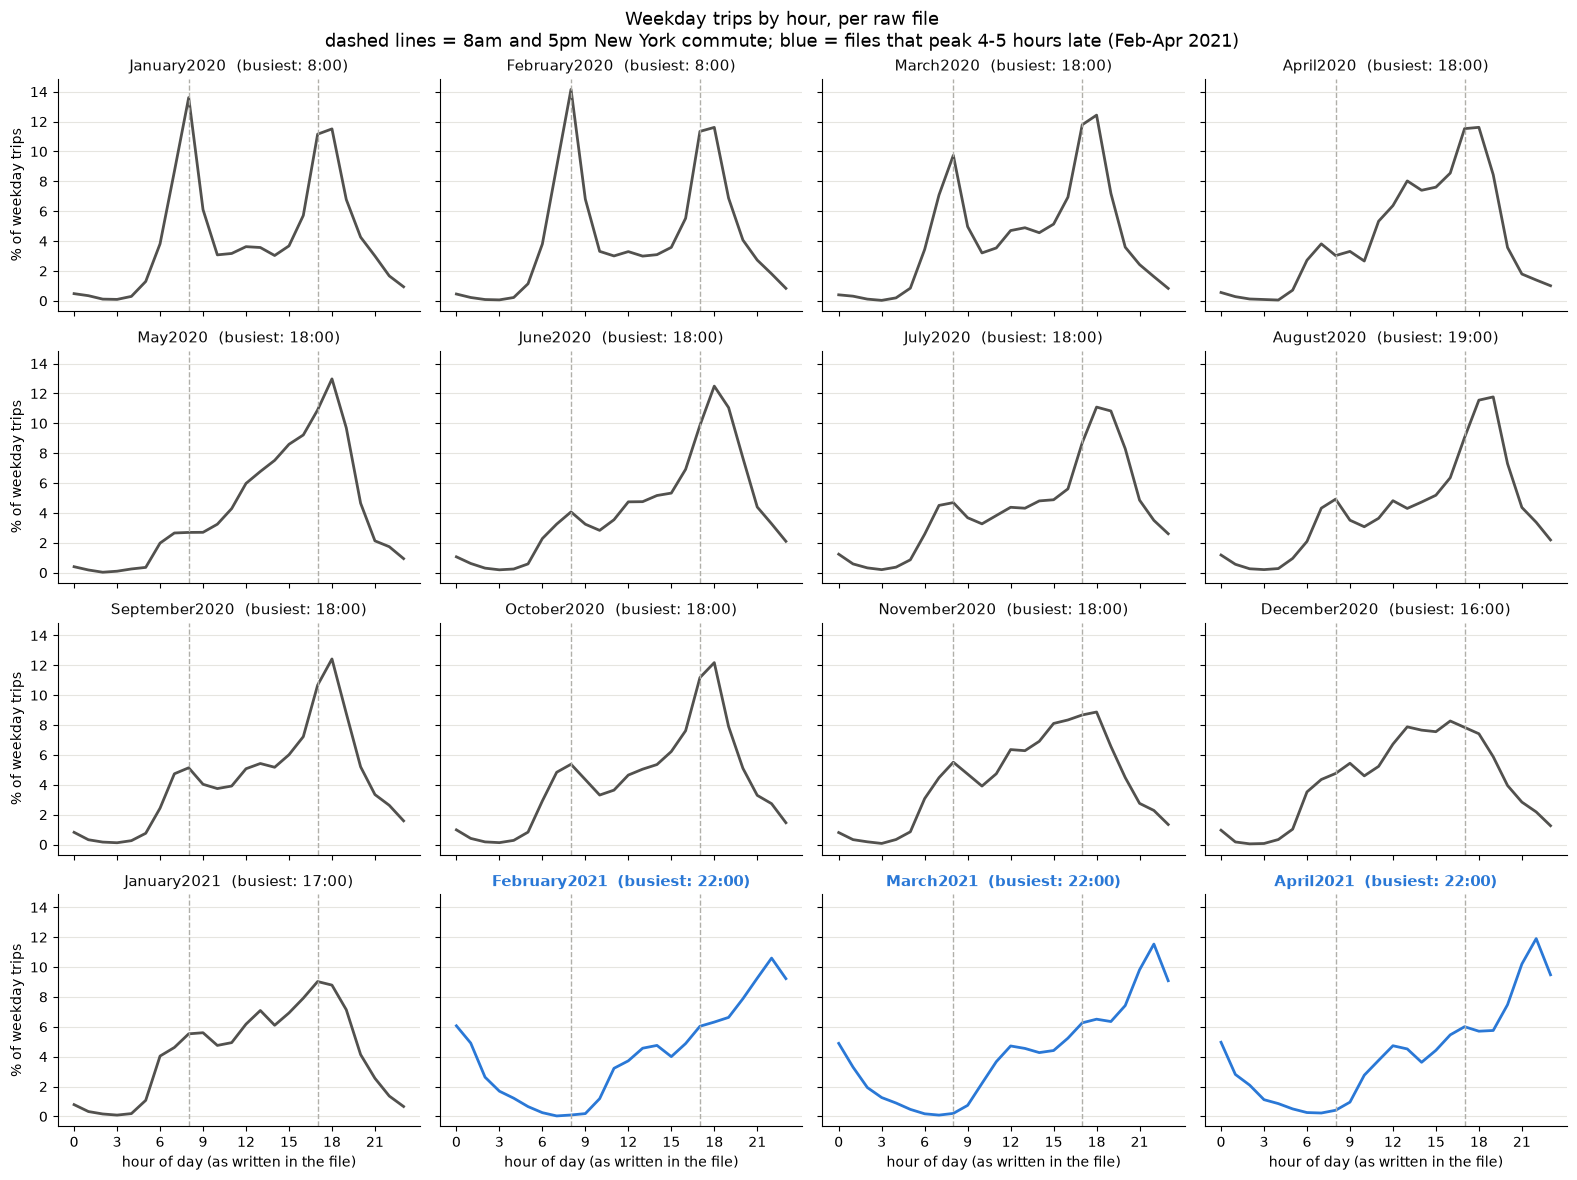

In [4]:
utc_files = ['February2021', 'March2021', 'April2021']

# one small chart per file: % of weekday trips starting in each hour
fig, axes = plt.subplots(4, 4, figsize = (16, 12), sharex = True, sharey = True)
for ax, month in zip(axes.flat, file_order):
    is_utc = month in utc_files
    line_color = '#2a78d6' if is_utc else '#52514e'

    ax.plot(hourly_share_df.columns, hourly_share_df.loc[month], color = line_color, linewidth = 2)

    # reference lines at the New York commute hours
    for commute_hour in [8, 17]:
        ax.axvline(commute_hour, color = '#b0afa9', linestyle = '--', linewidth = 1)

    busiest = hourly_share_df.loc[month].idxmax()
    ax.set_title(f'{month}  (busiest: {busiest}:00)', fontsize = 11,
                 color = line_color if is_utc else '#0b0b0b', fontweight = 'bold' if is_utc else 'normal')
    ax.set_xticks(range(0, 24, 3))
    ax.grid(axis = 'y', color = '#e6e5e0', linewidth = 0.8)
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes[-1]:
    ax.set_xlabel('hour of day (as written in the file)')
for ax in axes[:, 0]:
    ax.set_ylabel('% of weekday trips')

fig.suptitle('Weekday trips by hour, per raw file\n'
             'dashed lines = 8am and 5pm New York commute; blue = files that peak 4-5 hours late (Feb-Apr 2021)',
             fontsize = 13)
fig.tight_layout()
plt.show()

### Monthly trip patterns by hour, after converting Feb-Apr 2021 from UTC to New York time

Same chart as above, but the three UTC files are converted first. If the conversion is right, their peaks should line up with the other months.

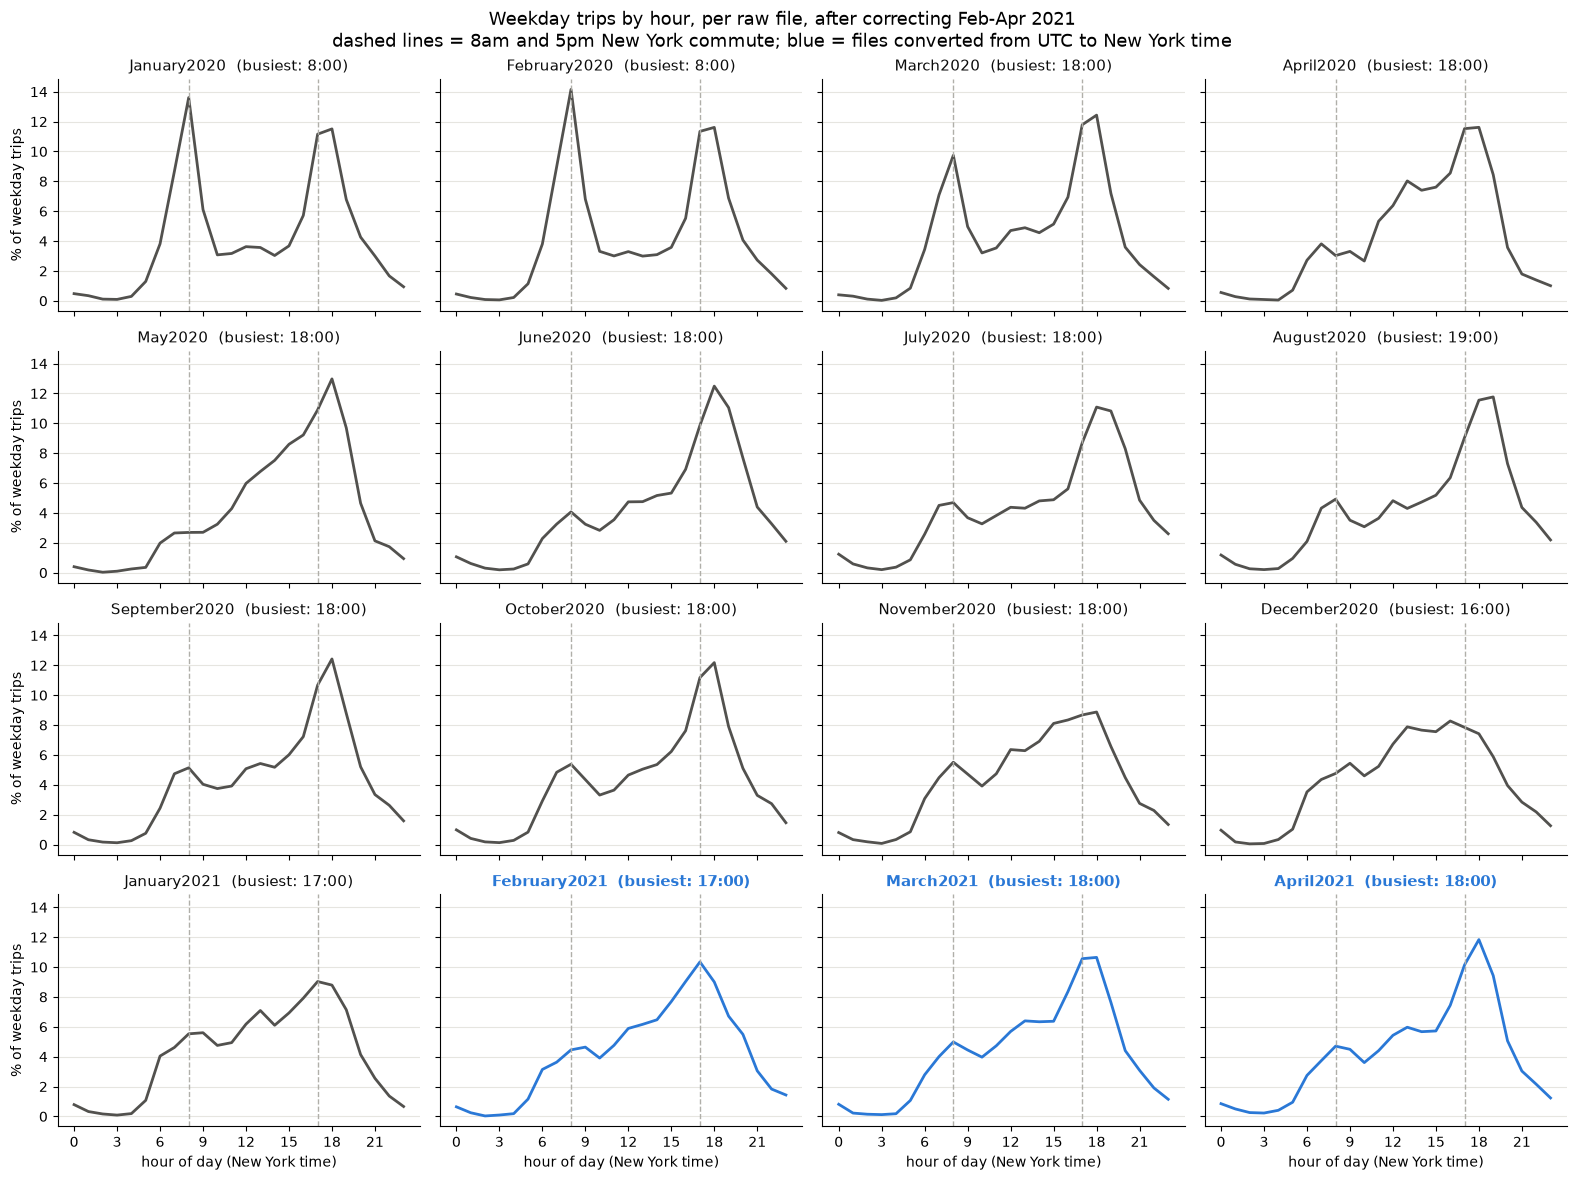

In [5]:
# convert only the Feb-Apr 2021 files from UTC to New York local time, then redraw the same chart
utc_files = ['February2021', 'March2021', 'April2021']

corrected_trips_df = trips_df.copy()
is_utc_file = corrected_trips_df['file'].isin(utc_files)
corrected_trips_df.loc[is_utc_file, 'starttime'] = (
    corrected_trips_df.loc[is_utc_file, 'starttime']
    .dt.tz_localize('UTC')
    .dt.tz_convert('America/New_York')
    .dt.tz_localize(None)
)
corrected_trips_df['hour'] = corrected_trips_df['starttime'].dt.hour

# weekdays only, using the corrected dates (a converted trip can move to the previous day)
corrected_weekday_df = corrected_trips_df[corrected_trips_df['starttime'].dt.dayofweek < 5]

# % of each file's weekday trips that start in each hour (each row adds up to 100)
corrected_share_df = (
    pd.crosstab(corrected_weekday_df['file'], corrected_weekday_df['hour'], normalize = 'index')
    .reindex(file_order) * 100
)

# one small chart per file, same layout as the uncorrected chart above
fig, axes = plt.subplots(4, 4, figsize = (16, 12), sharex = True, sharey = True)
for ax, month in zip(axes.flat, file_order):
    is_corrected = month in utc_files
    line_color = '#2a78d6' if is_corrected else '#52514e'

    ax.plot(corrected_share_df.columns, corrected_share_df.loc[month], color = line_color, linewidth = 2)

    # reference lines at the New York commute hours
    for commute_hour in [8, 17]:
        ax.axvline(commute_hour, color = '#b0afa9', linestyle = '--', linewidth = 1)

    busiest = corrected_share_df.loc[month].idxmax()
    ax.set_title(f'{month}  (busiest: {busiest}:00)', fontsize = 11,
                 color = line_color if is_corrected else '#0b0b0b', fontweight = 'bold' if is_corrected else 'normal')
    ax.set_xticks(range(0, 24, 3))
    ax.grid(axis = 'y', color = '#e6e5e0', linewidth = 0.8)
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes[-1]:
    ax.set_xlabel('hour of day (New York time)')
for ax in axes[:, 0]:
    ax.set_ylabel('% of weekday trips')

fig.suptitle('Weekday trips by hour, per raw file, after correcting Feb-Apr 2021\n'
             'dashed lines = 8am and 5pm New York commute; blue = files converted from UTC to New York time',
             fontsize = 13)
fig.tight_layout()
plt.show()